In [ ]:
from google.colab import drive
drive.mount('/content/drive/')

Mounted at /content/drive/


In [ ]:
cd /content/drive/MyDrive/project/

/content/drive/.shortcut-targets-by-id/1IhtrClOvYkKUSZxwUoLOhxwHY9CdXCaH/project


In [ ]:
!pip install ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 21.3 MB/s eta 0:00:00


# Define new yolo model

In [ ]:
cat ./tcdata/datasetNUMBER.yaml

names:
- number
nc: 1
path: ./tcdata
train: images/mchar_train
val: images/mchar_val


In [ ]:
ls ./tcdata

datasetNUMBER.yaml  labels2/                   mchar_test_a.zip  mchar_val.json
dataset.yaml        __MACOSX/                  mchar_train66/    mchar_val.zip
images/             mchar_data_list_0515.csv   mchar_train.json
labels/             mchar_sample_submit_A.csv  mchar_train.zip


In [ ]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [ ]:
# Reload the pretrained model
model = YOLO("runs/detect/number_v8/weights/last.pt")

model.train(
    data='./tcdata/datasetNUMBER.yaml',
    # epochs=20,
    epochs=10,
    imgsz=640,
    batch=64,
    patience=15,
    device='0',
    # resume=True,
    resume=False,

    # Loss tuning
    box=8.0,
    dfl=2.0,
    cls=0.6,
    kobj=1.3,

    # Training behaviour
    lr0=0.001,
    freeze=5,
    pretrained=True,
    augment=True,

    name='number_v8',
    project='runs/detect',
    exist_ok=True,
)

Ultralytics 8.3.241 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=True, auto_augment=randaugment, batch=64, bgr=0.0, box=8.0, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.6, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./tcdata/datasetNUMBER.yaml, degrees=0.0, deterministic=True, device=0, dfl=2.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=5, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.3, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=runs/detect/number_v8/weights/last.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=number_v8, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=15, perspective=0

KeyboardInterrupt: 

In [ ]:
# Reload the pretrained model
model = YOLO("runs/detect/number_v8/weights/last.pt")

"""
# Fine Tuning
model.train(
    data='./tcdata/datasetNUMBER.yaml',
    epochs=10,
    imgsz=640,
    batch=64,
    patience=15,
    device='0',

    # Loss tuning
    box=8.0,
    dfl=2.0,
    cls=0.6,
    kobj=1.3,

    # Training behaviour
    lr0=0.001,
    freeze=0,
    pretrained=True,
    augment=True,

    name='number_v8',
    project='runs/detect',
    exist_ok=True,
)"""

"\n# Fine Tuning\nmodel.train(\n    data='./tcdata/datasetNUMBER.yaml',\n    epochs=10,\n    imgsz=640,\n    batch=64,\n    patience=15,\n    device='0',\n\n    # Loss tuning\n    box=8.0,\n    dfl=2.0,\n    cls=0.6,\n    kobj=1.3,\n\n    # Training behaviour\n    lr0=0.001,\n    freeze=0,\n    pretrained=True,\n    augment=True,\n\n    name='number_v8',\n    project='runs/detect',\n    exist_ok=True,\n)"

# Change the detection result
Now yolo detects bounding boxes only with numbers, and we need to make yolo predict which number is in each bounding box. For that:


*   For each bounding box, crop the bb, and predict it with efficientNet
*   Change its label, and keep the result



In [ ]:
import cv2
import numpy as np

def predict_number(img, r):
    """For each prediction, crop the bounding box and predict the number, change its class"""

    if r.boxes is None or len(r.boxes) == 0:
        return None

    # Extract boxes, classes, and confidence scores
    boxes = r.boxes.xyxy.cpu().numpy()
    confs = r.boxes.conf.cpu().numpy()

    detections = []

    for box, conf in zip(boxes, confs):
        # Crop the image
        x1, y1, x2, y2 = map(int, box)  # Convert to integers for cropping
        # Ensure coordinates are within image bounds
        x1 = max(0, x1)
        y1 = max(0, y1)
        x2 = min(img.shape[1], x2)  # img.shape[1] is width
        y2 = min(img.shape[0], y2)  # img.shape[0] is height

        # Check if crop area is valid
        if x2 <= x1 or y2 <= y1:
            continue

        # Crop the region
        cropped_img = img[y1:y2, x1:x2]

        # classify_digit = EfficientNet-bo()
        predicted_digit = 1

        detections.append({
            "digit": predicted_digit,
            "x_center": (x1 + x2) / 2,
            "conf": conf
        })
    # Sort from left to right based on x_center
    detections.sort(key=lambda x: x["x_center"])

    # Create the number string
    number_str = "".join(str(d["digit"]) for d in detections)

    # Only return if we have digits
    if number_str:
        return int(number_str)
    return None

In [ ]:
import os
import zipfile
import cv2
import numpy as np

# --- PATH SETUP ---
PROJECT_ROOT = os.getcwd()

def predict():

    PROJECT_ROOT = os.getcwd()

    zip_file = os.path.join(PROJECT_ROOT, "tcdata", "mchar_test_a.zip")
    assert os.path.exists(zip_file), "ZIP not found"

    model = YOLO("runs/detect/number_v8/weights/best.pt")

    results_csv = []

    images = []
    names = []

    with zipfile.ZipFile(zip_file) as z:
      for name in sorted(z.namelist()):

          if name.endswith("/"):
              continue
          if not name.lower().endswith((".png", ".jpg", ".jpeg")):
              continue

          data = z.read(name)
          img = cv2.imdecode(np.frombuffer(data, np.uint8), cv2.IMREAD_COLOR)

          if img is None:
              continue

          img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

          images.append(img)
          names.append(os.path.basename(name))

    BATCH = 32
    for i in range(0, len(images), BATCH):
        batch_imgs = images[i:i+BATCH]
        batch_names = names[i:i+BATCH]

        # increasing imgsz to increase resolution and reduce confidence
        preds = model(batch_imgs, conf=0.1)

        for fname, img, r in zip(batch_names, batch_imgs, preds):
            number = predict_number(img, r)
            results_csv.append(f"{fname},{number if number else ''}")

        print(f"Processed {i+BATCH}/{len(images)}")

    out_file = os.path.join(PROJECT_ROOT, "prediction_result", "resultOLGA1.csv")
    with open(out_file, "w") as f:
      f.write("file_name,file_code\n")
      f.write("\n".join(results_csv))

    print(f"\nDone. Results saved to {out_file}")


In [ ]:

model = YOLO("runs/detect/number_v8/weights/best.pt")
test_set = os.path.join(PROJECT_ROOT, "tcdata", "images", "mchar_test_a")


image 1/1 /content/drive/.shortcut-targets-by-id/1IhtrClOvYkKUSZxwUoLOhxwHY9CdXCaH/project/tcdata/images/mchar_test_a/000100.png: 352x640 2 numbers, 111.4ms
Speed: 6.3ms preprocess, 111.4ms inference, 1.3ms postprocess per image at shape (1, 3, 352, 640)


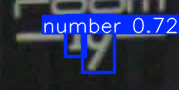

In [ ]:
import cv2
from PIL import Image
import matplotlib.pyplot as plt

# Realizar predicción
results = model(test_set+"/000100.png")

# Mostrar resultados automáticamente
results[0].show()  # Esto abrirá la imagen con los bounding boxes

In [ ]:
len(results[0].boxes)

2


image 1/1 /content/drive/MyDrive/project/tcdata/images/mchar_test_a/000010.png: 544x640 3 numbers, 44.3ms
Speed: 2.8ms preprocess, 44.3ms inference, 1.4ms postprocess per image at shape (1, 3, 544, 640)


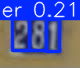

Número predicho: 111


In [ ]:
import cv2
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

# Ruta de la imagen
image_path = test_set + "/000010.png"

# 1. Cargar la imagen para usar en predict_number
# Opción A: Usando cv2 (lo que espera tu función)
img_cv2 = cv2.imread(image_path)
img_rgb = cv2.cvtColor(img_cv2, cv2.COLOR_BGR2RGB)  # Convertir a RGB

# Opción B: Usando PIL y convertir a numpy
# from PIL import Image
# img_pil = Image.open(image_path)
# img_rgb = np.array(img_pil)  # Convertir a numpy array

# 2. Realizar predicción con YOLO
results = model(image_path, conf=0.1)

# 3. Mostrar resultados
results[0].show()  # Muestra la imagen con bounding boxes

# 4. Llamar a predict_number CORRECTAMENTE
# Ahora pasamos tanto la imagen como los resultados
if len(results) > 0:
    a = predict_number(img_rgb, results[0])  # ¡Pasar ambos parámetros!
    print(f"Número predicho: {a}")
else:
    print("No se obtuvieron resultados")

# Predict result

In [ ]:
# Define Project root
from google.colab import drive
drive.mount('/content/drive/')

KeyboardInterrupt: 

In [ ]:
cd /content/drive/MyDrive/project/

/content/drive/MyDrive/project


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import transforms
import sys
import os

# --- PATH SETUP ---
PROJECT_ROOT = os.getcwd()

In [ ]:
predict()

流式输出内容被截断，只能显示最后 5000 行内容。
6: 640x640 3 numbers, 3.1ms
7: 640x640 2 numbers, 3.1ms
8: 640x640 3 numbers, 3.1ms
9: 640x640 3 numbers, 3.1ms
10: 640x640 2 numbers, 3.1ms
11: 640x640 2 numbers, 3.1ms
12: 640x640 (no detections), 3.1ms
13: 640x640 2 numbers, 3.1ms
14: 640x640 2 numbers, 3.1ms
15: 640x640 3 numbers, 3.1ms
16: 640x640 3 numbers, 3.1ms
17: 640x640 3 numbers, 3.1ms
18: 640x640 3 numbers, 3.1ms
19: 640x640 4 numbers, 3.1ms
20: 640x640 3 numbers, 3.1ms
21: 640x640 4 numbers, 3.1ms
22: 640x640 3 numbers, 3.1ms
23: 640x640 3 numbers, 3.1ms
24: 640x640 3 numbers, 3.1ms
25: 640x640 3 numbers, 3.1ms
26: 640x640 3 numbers, 3.1ms
27: 640x640 2 numbers, 3.1ms
28: 640x640 1 number, 3.1ms
29: 640x640 3 numbers, 3.1ms
30: 640x640 2 numbers, 3.1ms
31: 640x640 3 numbers, 3.1ms
Speed: 2.5ms preprocess, 3.1ms inference, 0.7ms postprocess per image at shape (1, 3, 640, 640)
Processed 35456/40000

0: 640x640 3 numbers, 3.1ms
1: 640x640 1 number, 3.1ms
2: 640x640 3 numbers, 3.1ms
3: 640x640 2 num